<a href="https://colab.research.google.com/github/matheusj4sus/pipeline-ml-body-fat/blob/main/Atividade_Integradora_Q1_Regressao_Gordura_Corporal_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atividade Integradora — Pipeline Completo de Machine Learning
## Questão 1 · Regressão: estimando o percentual de gordura corporal
### Tema: academia / avaliação física

**Disciplina:** Tópicos Avançados em Sistemas de Informação II — UNICID  
**Professor:** Prof. Me. Gabriel Rosa Paz  
**Alunos:** Matheus De Jesus Araujo e Daniel Vieira  
**Ambiente:** Google Colab · Python 3 · pandas · seaborn · scikit-learn

> Esta é a **Parte 1** da atividade (regressão: prever o **valor** do % de gordura). A Questão 2 (classificação) usa a **mesma base de dados** e está no notebook da **Parte 2**, onde o problema é classificar quem tem gordura elevada.

**Como executar:** menu *Ambiente de execução → Executar tudo*. O notebook baixa os dados sozinho; se a internet do Colab falhar, ele pede o upload do arquivo (instruções na própria célula).

### Sumário (segue a numeração do enunciado)
1. Escolha do dataset
2. Explicação do problema e do objetivo
3. Importação do dataset e separação de X e y
4. Análise exploratória (EDA)
5. Limpeza e pré-processamento
6. Gráficos e interpretação
7. Divisão em treino e teste
8. Algoritmos e hiperparâmetros
9. Necessidade de normalização
10. Comparação por métricas
11. Conclusão final

## 1) Escolha do dataset

| Item | Informação |
|---|---|
| **Nome** | *Fitting Percentage of Body Fat to Simple Body Measurements* (conhecido como **Body Fat**) |
| **Fonte original (documentação)** | Journal of Statistics Education (JSE) — Data Archive: https://jse.amstat.org/datasets/fat.txt |
| **Arquivo de dados** | https://jse.amstat.org/datasets/fat.dat.txt |
| **Artigo de referência** | Johnson, R. W. (1996). *Fitting Percentage of Body Fat to Simple Body Measurements*. Journal of Statistics Education, 4(1). |
| **Origem dos dados** | Dr. A. Garth Fisher, Human Performance Research Center, Brigham Young University (EUA), com permissão para distribuição livre e uso não comercial. Estudo original: Penrose, Nelson & Fisher (1985), *Medicine and Science in Sports and Exercise*, 17(2). |
| **Tamanho** | 252 homens · 19 variáveis originais |
| **Tipo de problema** | **Regressão** |

**Por que é um problema de regressão?** O target é o **percentual de gordura corporal**, uma grandeza numérica **contínua** (pode assumir qualquer valor, como 12,3 % ou 25,8 %), e não uma categoria.

**Por que é real e público?** São medições feitas em pessoas reais (pesagem subaquática e fita métrica), disponibilizadas publicamente pelo JSE, sem cadastro.

**Dataset não utilizado nas aulas:** este conjunto de dados não foi usado nos exemplos da disciplina.

## 2) Explicação do problema e do objetivo

**Domínio.** Avaliação física e composição corporal, um cenário típico de academias, em que o aluno acompanha a evolução do percentual de gordura. O método de referência (**pesagem hidrostática/subaquática**) é preciso, porém caro e inconveniente. Medidas com **balança e fita métrica** são baratas e rápidas.

| Pergunta | Resposta |
|---|---|
| **O que representa cada amostra?** | Um homem adulto avaliado fisicamente. |
| **Quais são as features?** | Idade, peso, altura e 10 circunferências corporais (pescoço, peito, abdômen, quadril, coxa, joelho, tornozelo, bíceps, antebraço e punho), em cm. |
| **Qual é o target?** | Percentual de gordura corporal calculado pela equação de Siri a partir da densidade corporal medida na pesagem subaquática. |
| **O que desejamos prever?** | O % de gordura corporal de uma pessoa usando apenas medidas simples. |
| **Qual é a fonte?** | JSE Data Archive (links na seção 1). |

**Objetivo do modelo.** Treinar e comparar modelos de regressão para estimar o % de gordura corporal com o menor erro possível, usando apenas medidas que uma academia obtém sem equipamento especial.

> ⚠️ **Uso educacional.** Este trabalho é um exercício de Machine Learning. O modelo **não** é uma ferramenta de diagnóstico clínico ou nutricional.

## 3) Importação do dataset e separação de X e y

O arquivo original **não tem cabeçalho**: cada linha é um homem e as colunas seguem a ordem descrita na documentação do JSE. Por isso os nomes das colunas são informados manualmente (`COLUNAS`).

### Decisão importante: evitar *target leakage* (vazamento do target)

Das 19 colunas, quatro **não podem** entrar em `X`:

| Coluna | Por que sai de X |
|---|---|
| `gordura_siri` | É o próprio **target** (y). |
| `gordura_brozek` | É a **mesma informação** calculada por outra fórmula a partir da mesma densidade (quase uma cópia do target). |
| `densidade` | O target é calculado **diretamente** dela: `495 / densidade − 450`. |
| `massa_magra_lb` | Calculada **usando** o % de gordura (`(1 − fração de gordura) × peso`), ou seja, embute o target. |

Além disso:
- `caso` é só um identificador e vira o **índice** do DataFrame;
- `indice_adiposidade` (peso/altura²) é função de peso e altura, que já estão em X, então sairia como redundância.

Deixar essas colunas daria um modelo "perfeito" no papel, mas **inútil na prática**: na academia não temos a densidade corporal, justamente o que queremos evitar medir.

In [ ]:
import io
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(42)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

In [ ]:
# Ordem das colunas conforme a documentação do JSE (https://jse.amstat.org/datasets/fat.txt)
COLUNAS = [
    "caso", "gordura_brozek", "gordura_siri", "densidade", "idade",
    "peso_lb", "altura_pol", "indice_adiposidade", "massa_magra_lb",
    "pescoco", "peito", "abdomen", "quadril", "coxa", "joelho",
    "tornozelo", "biceps", "antebraco", "punho",
]
FONTES = [
    "https://jse.amstat.org/datasets/fat.dat.txt",
    "http://jse.amstat.org/datasets/fat.dat.txt",
]


def ler_fonte(fonte):
    """Lê o arquivo (URL ou caminho local) e devolve um DataFrame numérico."""
    if fonte.startswith("http"):
        resposta = requests.get(fonte, headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
        resposta.raise_for_status()
        conteudo = io.StringIO(resposta.text)
    else:
        conteudo = fonte
    dados = pd.read_csv(conteudo, sep=r"\s+", header=None, names=COLUNAS)
    return dados.apply(pd.to_numeric, errors="raise")


def carregar_dados():
    for fonte in FONTES:
        try:
            dados = ler_fonte(fonte)
            if dados.shape == (252, len(COLUNAS)):
                return dados, fonte
            print(f"Formato inesperado em {fonte}: {dados.shape}")
        except Exception as erro:
            print(f"Falha ao ler {fonte}: {erro}")
    # Plano B: upload manual do arquivo fat.dat.txt (link na seção 1)
    from google.colab import files
    print("Baixe o arquivo fat.dat.txt pelo link da seção 1 e envie-o abaixo:")
    nome = next(iter(files.upload()))
    return ler_fonte(nome), nome


df_bruto, fonte_usada = carregar_dados()
df_bruto = df_bruto.set_index("caso")      # o número do caso vira o índice
print(f"Fonte utilizada: {fonte_usada}")
print(f"Formato do dataset original: {df_bruto.shape}")
df_bruto.head()

Fonte utilizada: https://jse.amstat.org/datasets/fat.dat.txt
Formato do dataset original: (252, 18)


,gordura_brozek,gordura_siri,densidade,idade,peso_lb,altura_pol,indice_adiposidade,massa_magra_lb,pescoco,peito,abdomen,quadril,coxa,joelho,tornozelo,biceps,antebraco,punho
caso,,,,,,,,,,,,,,,,,,
1,12.6,12.3,1.0708,23,154.25,67.75,23.7,134.9,36.2,93.1,85.2,94.5,59.0,37.3,21.9,32.0,27.4,17.1
2,6.9,6.1,1.0853,22,173.25,72.25,23.4,161.3,38.5,93.6,83.0,98.7,58.7,37.3,23.4,30.5,28.9,18.2
3,24.6,25.3,1.0414,22,154.00,66.25,24.7,116.0,34.0,95.8,87.9,99.2,59.6,38.9,24.0,28.8,25.2,16.6
4,10.9,10.4,1.0751,26,184.75,72.25,24.9,164.7,37.4,101.8,86.4,101.2,60.1,37.3,22.8,32.4,29.4,18.2
5,27.8,28.7,1.0340,24,184.25,71.25,25.6,133.1,34.4,97.3,100.0,101.9,63.2,42.2,24.0,32.2,27.7,17.7


In [ ]:
TARGET = "gordura_siri"
COLS_VAZAMENTO = ["gordura_brozek", "densidade", "massa_magra_lb"]
COLS_REDUNDANTES = ["indice_adiposidade"]

# Target e features
y = df_bruto[TARGET].copy()
X = df_bruto.drop(columns=[TARGET] + COLS_VAZAMENTO + COLS_REDUNDANTES).copy()

print("Features (X):", list(X.columns))
print("\nPrimeiras linhas de X:")
display(X.head())
print("Primeiros valores de y (% de gordura corporal):")
display(y.head())

Features (X): ['idade', 'peso_lb', 'altura_pol', 'pescoco', 'peito', 'abdomen', 'quadril', 'coxa', 'joelho', 'tornozelo', 'biceps', 'antebraco', 'punho']

Primeiras linhas de X:


,idade,peso_lb,altura_pol,pescoco,peito,abdomen,quadril,coxa,joelho,tornozelo,biceps,antebraco,punho
caso,,,,,,,,,,,,,
1,23,154.25,67.75,36.2,93.1,85.2,94.5,59.0,37.3,21.9,32.0,27.4,17.1
2,22,173.25,72.25,38.5,93.6,83.0,98.7,58.7,37.3,23.4,30.5,28.9,18.2
3,22,154.00,66.25,34.0,95.8,87.9,99.2,59.6,38.9,24.0,28.8,25.2,16.6
4,26,184.75,72.25,37.4,101.8,86.4,101.2,60.1,37.3,22.8,32.4,29.4,18.2
5,24,184.25,71.25,34.4,97.3,100.0,101.9,63.2,42.2,24.0,32.2,27.7,17.7


Primeiros valores de y (% de gordura corporal):


,gordura_siri
caso,
1,12.3
2,6.1
3,25.3
4,10.4
5,28.7


## 4) Análise exploratória (EDA)

Antes de qualquer transformação, vamos entender **estrutura, tipos, escala e qualidade** dos dados: formato (`shape`), tipos (`info`), resumo estatístico (`describe`), valores ausentes (`isnull`) e duplicidades (`duplicated`).

In [ ]:
print("Dimensão de X (linhas, colunas):", X.shape)
print("\nTipos de dados e não-nulos:")
X.info()
print("\nEstatísticas descritivas de X:")
display(X.describe().T)
print("\nValores nulos por coluna:")
print(X.isnull().sum())
print("\nLinhas duplicadas em X:", X.duplicated().sum())
print("\nEstatísticas do target (% de gordura corporal):")
display(y.describe().to_frame().T)

Dimensão de X (linhas, colunas): (252, 13)

Tipos de dados e não-nulos:
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 1 to 252
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   idade       252 non-null    int64  
 1   peso_lb     252 non-null    float64
 2   altura_pol  252 non-null    float64
 3   pescoco     252 non-null    float64
 4   peito       252 non-null    float64
 5   abdomen     252 non-null    float64
 6   quadril     252 non-null    float64
 7   coxa        252 non-null    float64
 8   joelho      252 non-null    float64
 9   tornozelo   252 non-null    float64
 10  biceps      252 non-null    float64
 11  antebraco   252 non-null    float64
 12  punho       252 non-null    float64
dtypes: float64(12), int64(1)
memory usage: 27.6 KB

Estatísticas descritivas de X:


,count,mean,std,min,25%,50%,75%,max
idade,252.0,44.884921,12.602040,22.0,35.750,43.00,54.000,81.00
peso_lb,252.0,178.924405,29.389160,118.5,159.000,176.50,197.000,363.15
altura_pol,252.0,70.148810,3.662856,29.5,68.250,70.00,72.250,77.75
pescoco,252.0,37.992063,2.430913,31.1,36.400,38.00,39.425,51.20
peito,252.0,100.824206,8.430476,79.3,94.350,99.65,105.375,136.20
abdomen,252.0,92.555952,10.783077,69.4,84.575,90.95,99.325,148.10
quadril,252.0,99.904762,7.164058,85.0,95.500,99.30,103.525,147.70
coxa,252.0,59.405952,5.249952,47.2,56.000,59.00,62.350,87.30
joelho,252.0,38.590476,2.411805,33.0,36.975,38.50,39.925,49.10
tornozelo,252.0,23.102381,1.694893,19.1,22.000,22.80,24.000,33.90



Valores nulos por coluna:
idade         0
peso_lb       0
altura_pol    0
pescoco       0
peito         0
abdomen       0
quadril       0
coxa          0
joelho        0
tornozelo     0
biceps        0
antebraco     0
punho         0
dtype: int64

Linhas duplicadas em X: 0

Estatísticas do target (% de gordura corporal):


,count,mean,std,min,25%,50%,75%,max
gordura_siri,252.0,19.150794,8.36874,0.0,12.475,19.2,25.3,47.5


In [ ]:
altura_min = X["altura_pol"].min()
amplitudes = X.max() - X.min()

print("DIAGNÓSTICO DA EDA")
print(f"• Amostras x features: {X.shape[0]} x {X.shape[1]}")
print(f"• Valores nulos (total em X): {int(X.isnull().sum().sum())} | nulos em y: {int(y.isnull().sum())}")
print(f"• Linhas duplicadas em X: {int(X.duplicated().sum())}")
print(f"• Altura mínima: {altura_min:.1f} pol = {altura_min * 2.54:.0f} cm  ->  "
      f"{'IMPLAUSÍVEL para um adulto' if altura_min < 48 else 'plausível'}")
print(f"• Registros com % de gordura <= 0: {int((y <= 0).sum())}")
print(f"• Maior amplitude: {amplitudes.idxmax()} ({amplitudes.max():.0f}) | "
      f"menor amplitude: {amplitudes.idxmin()} ({amplitudes.min():.0f})")

DIAGNÓSTICO DA EDA
• Amostras x features: 252 x 13
• Valores nulos (total em X): 0 | nulos em y: 0
• Linhas duplicadas em X: 0
• Altura mínima: 29.5 pol = 75 cm  ->  IMPLAUSÍVEL para um adulto
• Registros com % de gordura <= 0: 1
• Maior amplitude: peso_lb (245) | menor amplitude: punho (6)


### Interpretação da EDA

- **Tipos:** todas as features são numéricas, então **não é necessário codificar categorias** (one-hot).
- **Nulos e duplicidades:** conforme a contagem acima, a base está completa e sem linhas repetidas; **não há o que imputar nem remover** nesses dois quesitos.
- **Escalas muito diferentes:** peso (em libras) varia em dezenas de unidades, enquanto punho ou tornozelo variam em poucos centímetros. Isso importa para algoritmos baseados em distância (seção 9).
- **Problemas de qualidade encontrados:** a documentação do JSE avisa que há erros pontuais, e a EDA os confirma: uma **altura impossível** (menos de 1 m para um adulto de mais de 90 kg) e **valores de gordura truncados em zero**. Também há registros em que as duas fórmulas de gordura (Brozek e Siri) deveriam coincidir e não coincidem. Esses pontos são tratados na seção 5.
- **Unidades:** peso em libras e altura em polegadas; vamos converter para kg e cm, pois o contexto (academia no Brasil) e a interpretação ficam mais naturais.

## 5) Limpeza e pré-processamento

Cada decisão abaixo é **justificada**, e nada é aplicado "no automático":

| # | Decisão | Justificativa |
|---|---|---|
| 5.1 | **Corrigir a altura do caso 42** (29,5 → 69,5 pol) | Erro de digitação documentado pelos autores ("presumivelmente 69,5"). Um adulto de ~90 kg com 75 cm de altura é impossível. Corrigir preserva uma linha válida. |
| 5.2 | **Remover linhas com target não confiável**: (a) % de gordura ≤ 0 e (b) Brozek e Siri incoerentes | (a) 0 % de gordura é fisiologicamente implausível e foi truncado na origem. (b) As duas fórmulas derivam da mesma densidade (`Siri = 495·(Brozek + 414,2)/457 − 450`); diferença maior que 1 p.p. indica erro de digitação na densidade (a documentação cita os casos 48, 76 e 96) e não sabemos qual valor está certo. Prefiro perder poucas linhas a treinar com alvo errado. |
| 5.3 | **Converter unidades** (lb → kg, pol → cm) | Conversão fixa (não aprendida dos dados), logo **não causa data leakage**. |
| 5.4 | **Duplicidades** | Remover se existirem. |
| 5.5 | **Nulos** | Se existissem, usaria `SimpleImputer` **dentro do Pipeline** (ajustado só no treino). |
| 5.6 | **Outliers estatísticos: não remover** | Homens muito grandes ou com alto % de gordura são **reais e válidos**. Só removo o que é **erro comprovado**, não o que é apenas extremo. |
| 5.7 | **Padronização (StandardScaler)** | **Não aplico aqui.** Ela vai dentro de `Pipeline` e só nos modelos sensíveis à escala, ajustada **apenas no treino** (e, na validação cruzada, apenas em cada fold de treino). |

> **Por que limpar antes de dividir treino/teste?** As etapas 5.1 a 5.4 são regras **determinísticas** (documentação, física e coerência entre fórmulas), não estatísticas aprendidas do conjunto. Nada delas "enxerga" o teste para aprender algo. Já as transformações que **aprendem** parâmetros dos dados (média e desvio da padronização, medianas de imputação) ficam no Pipeline.

Registros com altura < 48 pol (≈ 1,22 m):


,idade,peso_lb,altura_pol
caso,,,
42,44,205.0,29.5


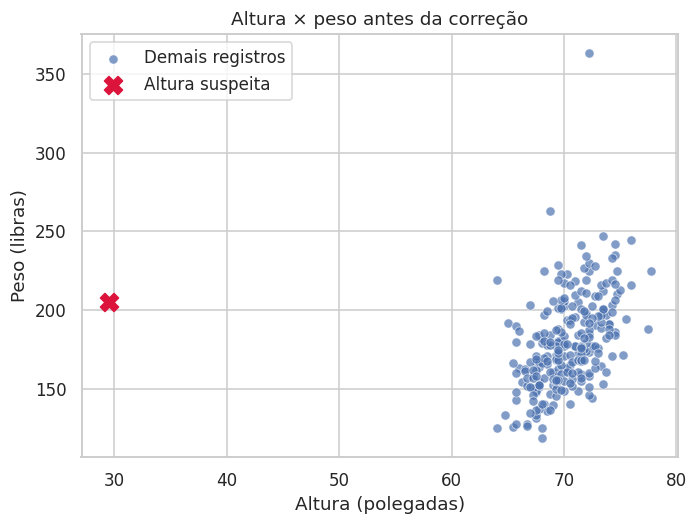

Altura mínima após a correção: 64.0 pol


In [ ]:
# 5.1 Altura impossível ---------------------------------------------------------
mask_altura = X["altura_pol"] < 48
print("Registros com altura < 48 pol (≈ 1,22 m):")
display(X.loc[mask_altura, ["idade", "peso_lb", "altura_pol"]])

fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(x=X.loc[~mask_altura, "altura_pol"], y=X.loc[~mask_altura, "peso_lb"],
                ax=ax, alpha=0.7, label="Demais registros")
if mask_altura.any():
    ax.scatter(X.loc[mask_altura, "altura_pol"], X.loc[mask_altura, "peso_lb"],
               color="crimson", s=140, marker="X", label="Altura suspeita")
ax.set(title="Altura × peso antes da correção",
       xlabel="Altura (polegadas)", ylabel="Peso (libras)")
ax.legend()
plt.show()

if 42 in X.index:
    X.loc[42, "altura_pol"] = 69.5          # correção documentada pelos autores
print("Altura mínima após a correção:", X["altura_pol"].min(), "pol")

**Interpretação.** O gráfico mostra o ponto isolado à esquerda de todos os demais: peso normal para a amostra, mas altura incompatível com a de um adulto. Como é um erro de digitação documentado (e não um caso extremo real), corrigimos o valor em vez de descartar a linha.

In [ ]:
# 5.2 Linhas com target não confiável ------------------------------------------
invalido_alvo = y[y <= 0].index

siri_esperado = 495 * (df_bruto["gordura_brozek"] + 414.2) / 457 - 450   # Siri implícito no Brozek
incoerente = (df_bruto["gordura_siri"] - siri_esperado).abs() > 1.0
incoerente = incoerente[incoerente].index

a_remover = invalido_alvo.union(incoerente)
print(f"Target <= 0 (truncado na origem): {list(invalido_alvo)}")
print(f"Brozek x Siri incoerentes (|diferença| > 1 p.p.): {list(incoerente)}")
print(f"Total removido: {len(a_remover)} de {len(X)} linhas ({len(a_remover) / len(X):.1%})")

X = X.drop(index=a_remover)
y = y.drop(index=a_remover)

Target <= 0 (truncado na origem): [182]
Brozek x Siri incoerentes (|diferença| > 1 p.p.): [33, 169, 182]
Total removido: 3 de 252 linhas (1.2%)


In [ ]:
# 5.3 Conversão de unidades (regra fixa, sem aprender nada dos dados) -------------
X["peso_kg"] = X["peso_lb"] * 0.45359237
X["altura_cm"] = X["altura_pol"] * 2.54
X = X.drop(columns=["peso_lb", "altura_pol"])
X = X[["idade", "peso_kg", "altura_cm", "pescoco", "peito", "abdomen", "quadril",
       "coxa", "joelho", "tornozelo", "biceps", "antebraco", "punho"]]

# 5.4 Duplicidades -------------------------------------------------------------
mask_dup = X.duplicated()
print(f"Duplicidades encontradas: {int(mask_dup.sum())}")
if mask_dup.any():
    X, y = X[~mask_dup], y[~mask_dup]

# 5.5 Nulos ------------------------------------------------------------------
print(f"Nulos restantes em X: {int(X.isnull().sum().sum())} | em y: {int(y.isnull().sum())}")

assert X.index.equals(y.index)
print("\nFormato final de X e y:", X.shape, y.shape)
display(X.describe().T[["mean", "std", "min", "max"]].round(2))

Duplicidades encontradas: 0
Nulos restantes em X: 0 | em y: 0

Formato final de X e y: (249, 13) (249,)


,mean,std,min,max
idade,45.02,12.61,22.00,81.00
peso_kg,81.20,13.22,56.70,164.72
altura_cm,178.60,6.65,162.56,197.48
pescoco,38.00,2.43,31.10,51.20
peito,100.89,8.31,83.40,136.20
abdomen,92.61,10.61,70.40,148.10
quadril,99.94,7.10,85.30,147.70
coxa,59.40,5.14,49.30,87.30
joelho,38.61,2.40,33.00,49.10
tornozelo,23.10,1.69,19.10,33.90


## 6) Gráficos e interpretação

Cada gráfico responde a uma pergunta sobre os dados, com título, eixos identificados e leitura textual. (Aqui usamos o conjunto completo **só para exploração**; nenhuma transformação é aprendida a partir dele.)

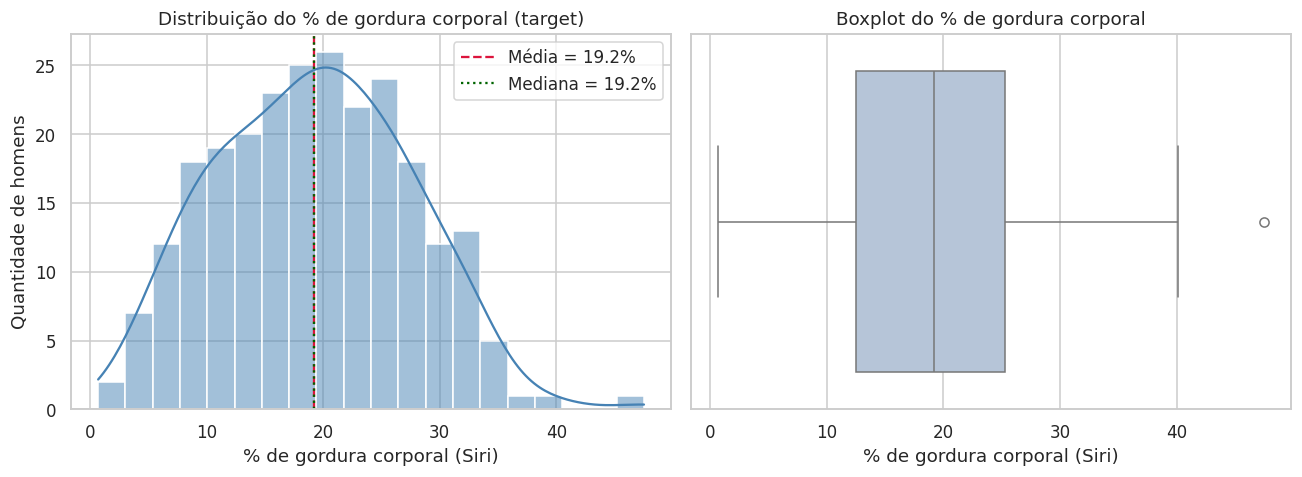

Leitura automática: média 19.2% | mediana 19.2% | desvio padrão 8.3 p.p. | assimetria 0.17 | mín 0.7% | máx 47.5%


In [ ]:
df_viz = X.copy()
df_viz[TARGET] = y

# Gráfico 1 — distribuição do target
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(y, bins=20, kde=True, color="steelblue", ax=axes[0])
axes[0].axvline(y.mean(), color="crimson", linestyle="--", label=f"Média = {y.mean():.1f}%")
axes[0].axvline(y.median(), color="darkgreen", linestyle=":", label=f"Mediana = {y.median():.1f}%")
axes[0].set(title="Distribuição do % de gordura corporal (target)",
            xlabel="% de gordura corporal (Siri)", ylabel="Quantidade de homens")
axes[0].legend()
sns.boxplot(x=y, color="lightsteelblue", ax=axes[1])
axes[1].set(title="Boxplot do % de gordura corporal", xlabel="% de gordura corporal (Siri)")
plt.tight_layout()
plt.show()

print(f"Leitura automática: média {y.mean():.1f}% | mediana {y.median():.1f}% | "
      f"desvio padrão {y.std():.1f} p.p. | assimetria {y.skew():.2f} | "
      f"mín {y.min():.1f}% | máx {y.max():.1f}%")

**Por que este gráfico?** Em regressão, o primeiro passo é conhecer o target: histograma + KDE mostram forma e assimetria; o boxplot destaca valores extremos.

**O que revela.**
- A distribuição é concentrada numa faixa central, com **cauda para a direita** (poucos homens com percentual bem alto). Média e mediana próximas indicam assimetria leve.
- Não há valores negativos nem acima do plausível depois da limpeza.
- O **desvio padrão do target** (em pontos percentuais) é a referência para julgar os modelos: um modelo só é útil se errar **bem menos** que a variação natural dos dados (ver baseline na seção 8).

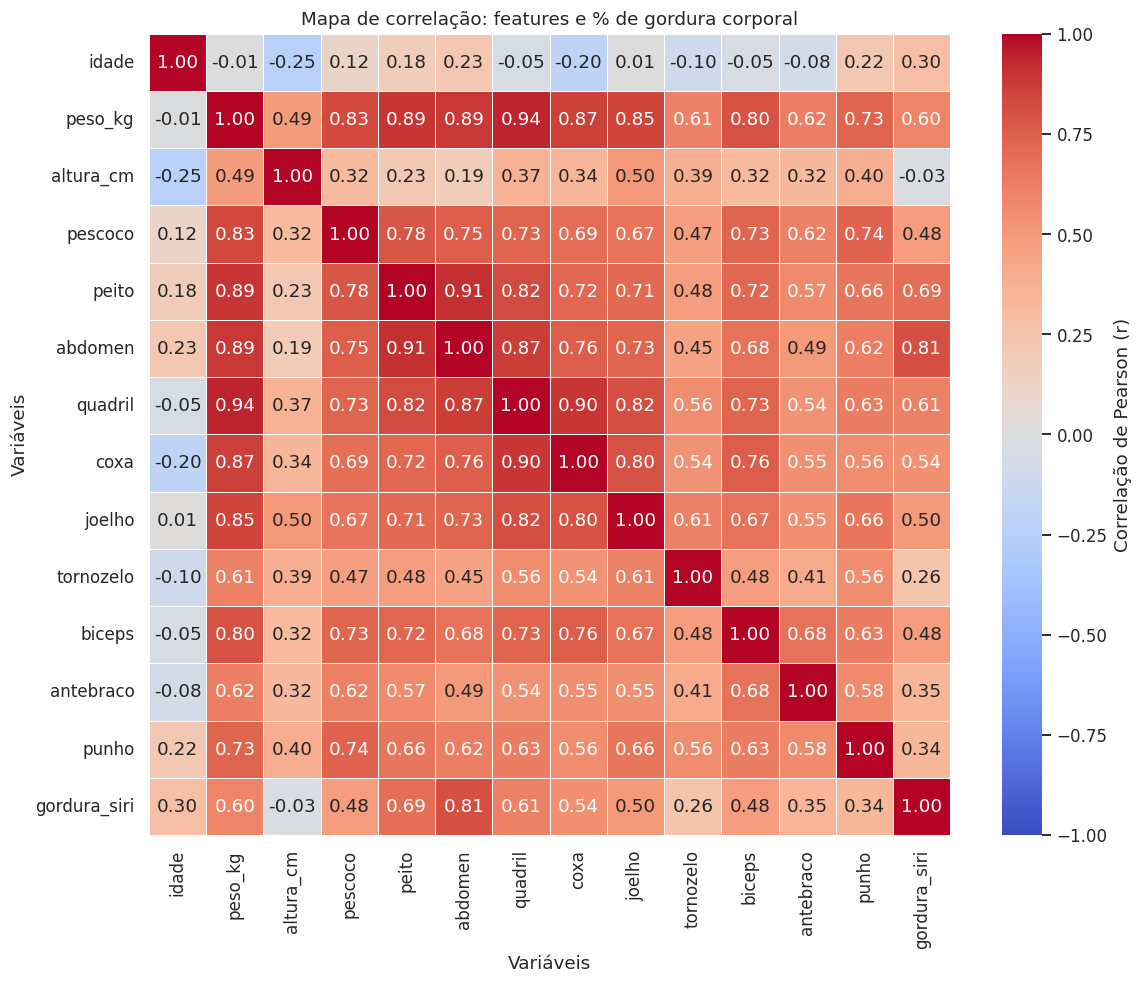

Correlação de cada feature com o target:
abdomen      0.81
peito        0.69
quadril      0.61
peso_kg      0.60
coxa         0.54
joelho       0.50
pescoco      0.48
biceps       0.48
antebraco    0.35
punho        0.34
idade        0.30
tornozelo    0.26
altura_cm   -0.03

Pares de features com |r| > 0,80 (possível multicolinearidade): 12
  peso_kg x quadril: r = 0.94
  peito x abdomen: r = 0.91
  quadril x coxa: r = 0.90
  peso_kg x peito: r = 0.89
  peso_kg x abdomen: r = 0.89
  abdomen x quadril: r = 0.87
  peso_kg x coxa: r = 0.87
  peso_kg x joelho: r = 0.85


In [ ]:
# Gráfico 2 — correlações entre todas as variáveis
corr = df_viz.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"label": "Correlação de Pearson (r)"})
plt.title("Mapa de correlação: features e % de gordura corporal")
plt.xlabel("Variáveis")
plt.ylabel("Variáveis")
plt.tight_layout()
plt.show()

corr_alvo = corr[TARGET].drop(TARGET).sort_values(ascending=False)
print("Correlação de cada feature com o target:")
print(corr_alvo.round(2).to_string())

corr_feat = X.corr()
pares = []
for i, a in enumerate(X.columns):
    for b in X.columns[i + 1:]:
        if abs(corr_feat.loc[a, b]) > 0.8:
            pares.append((a, b, corr_feat.loc[a, b]))
pares.sort(key=lambda t: -abs(t[2]))
print(f"\nPares de features com |r| > 0,80 (possível multicolinearidade): {len(pares)}")
for a, b, r in pares[:8]:
    print(f"  {a} x {b}: r = {r:.2f}")

**Por que este gráfico?** O mapa de calor mostra, de uma só vez, (i) quais medidas se relacionam com o target e (ii) quais features são redundantes entre si.

**O que revela.**
- As variáveis de **tamanho/volume do tronco** (abdômen, peito, quadril, peso) têm correlação positiva com o % de gordura: quem tem mais gordura acumulada tende a ter circunferências maiores. O **abdômen** costuma ser o mais forte, o que é coerente fisiologicamente.
- A **altura** tem relação muito fraca com o target: ser alto não significa ter mais gordura.
- Muitas features são **fortemente correlacionadas entre si** (peso, quadril, coxa, peito, abdômen, joelho). Isso é **multicolinearidade**: dificulta interpretar coeficientes da regressão linear, mas não impede boa previsão, e árvores/Random Forest lidam bem com isso.

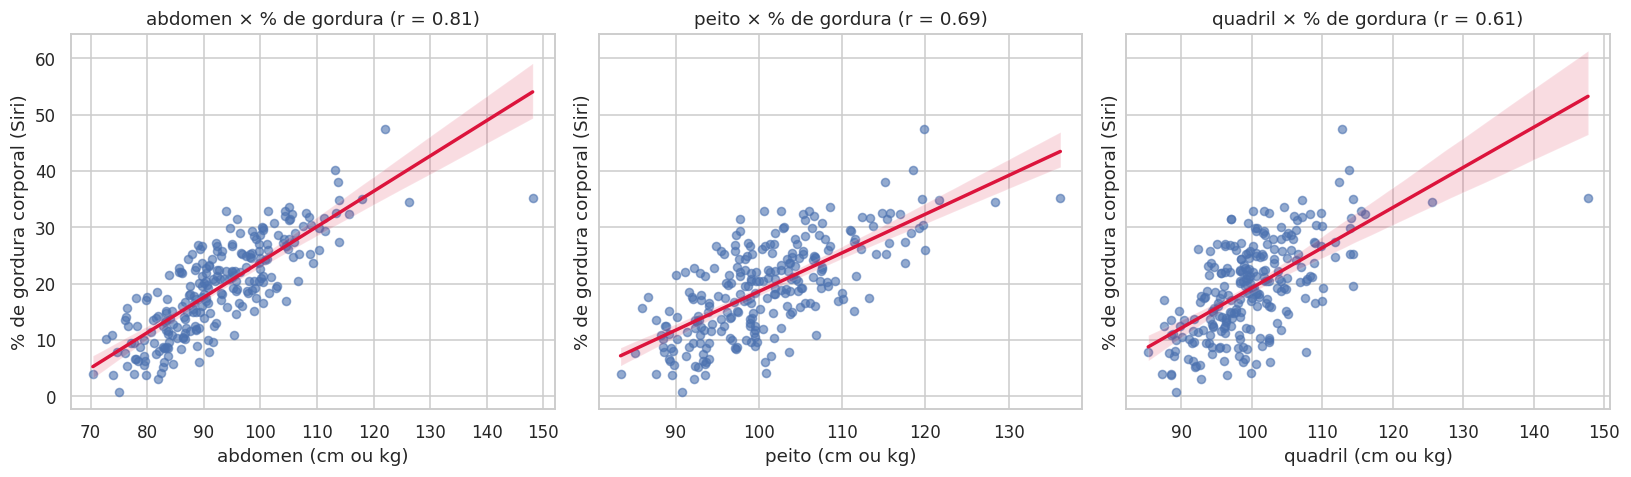

In [ ]:
# Gráfico 3 — relação das 3 features mais associadas com o target
top3 = corr_alvo.abs().sort_values(ascending=False).index[:3]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, feat in zip(axes, top3):
    sns.regplot(x=df_viz[feat], y=df_viz[TARGET], ax=ax,
                scatter_kws={"alpha": 0.6, "s": 28}, line_kws={"color": "crimson"})
    ax.set(title=f"{feat} × % de gordura (r = {corr_alvo[feat]:.2f})",
           xlabel=f"{feat} (cm ou kg)", ylabel="% de gordura corporal (Siri)")
plt.tight_layout()
plt.show()

**Por que este gráfico?** O scatter com reta de regressão mostra **a forma** da relação (linear, curva, dispersa), algo que o número da correlação sozinho não revela.

**O que revela.**
- As nuvens de pontos **sobem da esquerda para a direita**, com tendência aproximadamente **linear**: sinal de que a regressão linear deve funcionar bem.
- Há **dispersão** em torno da reta, ou seja, mesmo a melhor medida isolada **não explica tudo**. Combinar várias medidas (como os modelos fazem) deve reduzir o erro.

## 7) Divisão em treino e teste

- **80 % treino / 20 % teste** com `random_state=42` (resultado reprodutível).
- **Sem `stratify`**, porque o target é contínuo (estratificação é para classes).
- O **conjunto de teste fica "trancado"**: não participa de ajuste de transformações nem da escolha de hiperparâmetros. Ele serve apenas para a avaliação final, o que garante uma **avaliação justa**.

In [ ]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(f"Treino: {X_treino.shape[0]} linhas | Teste: {X_teste.shape[0]} linhas")
print("\nO target tem distribuição parecida nos dois conjuntos?")
display(pd.DataFrame({"treino": y_treino.describe(), "teste": y_teste.describe()}).round(2).T)

Treino: 199 linhas | Teste: 50 linhas

O target tem distribuição parecida nos dois conjuntos?


,count,mean,std,min,25%,50%,75%,max
treino,199.0,19.18,8.39,0.7,12.50,19.2,25.45,47.5
teste,50.0,19.27,7.80,3.7,13.18,19.8,24.45,34.8


## 8) Algoritmos e hiperparâmetros

### Algoritmos escolhidos

| Algoritmo | Por que escolhi | O que espero | Sensível à escala? | Hiperparâmetros testados |
|---|---|---|---|---|
| **Baseline** (`DummyRegressor`, prevê a média) | Referência mínima de comparação | R² ≈ 0; qualquer modelo útil deve superá-lo | Não | — |
| **Regressão Linear** | Simples, interpretável; os gráficos mostraram relação aproximadamente linear | Bom desempenho; estável | Pouco (previsões iguais; só os coeficientes mudam) | `fit_intercept` (padrão) |
| **Árvore de Decisão** | Captura não linearidades e interações; fácil de explicar | Tende a **superajustar** se ficar profunda | Não | `max_depth`, `min_samples_leaf` |
| **KNN** | Estima o % de gordura olhando pessoas com medidas parecidas | Competitivo se as variáveis estiverem na mesma escala | **Sim** | `n_neighbors`, `weights` |
| **Random Forest** | Conjunto de árvores: reduz variância e o superajuste de uma árvore isolada | Bom e estável | Não | `n_estimators`, `max_features` |
| **SGD** (`SGDRegressor`) | Aprende por gradiente, em passos pequenos; mostra o efeito da taxa de aprendizagem | Sensível a `eta0` e ao nº de iterações; pode não convergir | **Sim** | `eta0`, `max_iter` |
| **SVR** | Regressão por margem, com kernel linear ou curvo (rbf) | Bom com padronização; sensível a `C` e ao kernel | **Sim** | `kernel`, `C` |

### Como escolho hiperparâmetros sem "espiar" o teste

Usei **validação cruzada de 5 folds** (`KFold(shuffle=True, random_state=42)`) **somente dentro do treino**. A **escolha** da melhor configuração é feita pelo **RMSE da validação cruzada**. O teste serve para reportar o desempenho final: mostro as métricas de teste de todas as configurações porque a atividade pede a comparação, mas **não escolho com base nelas**.

Onde há padronização, ela fica dentro de um `Pipeline`: em cada fold, o `StandardScaler` aprende média e desvio **só dos dados de treino daquele fold**, evitando *data leakage*.

> Regra de organização: altero **um hiperparâmetro por vez** e registro tudo numa tabela de resultados.

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
resultados = []     # tabela de experimentos
modelos = {}        # modelos treinados + previsões no teste


def medir(modelo):
    """RMSE em validação cruzada (treino) e métricas no teste."""
    cv_rmse = -cross_val_score(modelo, X_treino, y_treino, cv=kf,
                               scoring="neg_root_mean_squared_error")
    modelo.fit(X_treino, y_treino)
    prev = modelo.predict(X_teste)
    return {
        "cv_rmse": cv_rmse.mean(),
        "cv_desvio": cv_rmse.std(),
        "mae_teste": mean_absolute_error(y_teste, prev),
        "rmse_teste": np.sqrt(mean_squared_error(y_teste, prev)),
        "r2_teste": r2_score(y_teste, prev),
        "prev": prev,
    }


def registrar(familia, hiper, modelo):
    m = medir(modelo)
    resultados.append({"familia": familia, "hiperparametros": hiper,
                       **{k: v for k, v in m.items() if k != "prev"}})
    modelos[(familia, hiper)] = (modelo, m["prev"])


def mostrar(familia):
    tabela = pd.DataFrame(resultados).query("familia == @familia").drop(columns="familia")
    display(tabela.round(3).reset_index(drop=True))


def com_escala(estimador):
    return Pipeline([("escala", StandardScaler()), ("modelo", estimador)])

In [ ]:
# Baseline e Regressão Linear
registrar("Baseline (média)", "strategy='mean'", DummyRegressor(strategy="mean"))
registrar("Regressão Linear", "fit_intercept=True (com escala)", com_escala(LinearRegression()))
mostrar("Baseline (média)")
mostrar("Regressão Linear")

,hiperparametros,cv_rmse,cv_desvio,mae_teste,rmse_teste,r2_teste
0,strategy='mean',8.341,0.785,6.393,7.721,-0.0


,hiperparametros,cv_rmse,cv_desvio,mae_teste,rmse_teste,r2_teste
0,fit_intercept=True (com escala),4.806,0.28,3.127,3.87,0.749


In [ ]:
# Árvore de Decisão — experimento 1: profundidade máxima
for prof in [2, 3, 5, 10]:
    registrar("Árvore de Decisão", f"max_depth={prof}",
              DecisionTreeRegressor(max_depth=prof, random_state=42))

# Árvore de Decisão — experimento 2: tamanho mínimo da folha (sem limite de profundidade)
for folha in [1, 5, 10, 20]:
    registrar("Árvore de Decisão", f"max_depth=None, min_samples_leaf={folha}",
              DecisionTreeRegressor(max_depth=None, min_samples_leaf=folha, random_state=42))

mostrar("Árvore de Decisão")

,hiperparametros,cv_rmse,cv_desvio,mae_teste,rmse_teste,r2_teste
0,max_depth=2,5.663,0.658,3.525,4.328,0.686
1,max_depth=3,5.612,0.869,4.148,5.413,0.508
2,max_depth=5,5.894,0.811,4.603,5.923,0.412
3,max_depth=10,6.428,0.983,5.092,6.148,0.366
4,"max_depth=None, min_samples_leaf=1",6.606,0.924,4.920,6.322,0.329
5,"max_depth=None, min_samples_leaf=5",5.901,0.819,3.825,5.113,0.562
6,"max_depth=None, min_samples_leaf=10",5.388,0.781,4.412,5.608,0.472
7,"max_depth=None, min_samples_leaf=20",5.413,0.772,3.754,4.550,0.653


**Leitura da árvore.** `max_depth` e `min_samples_leaf` controlam a **complexidade**: árvore muito profunda (ou com folhas minúsculas) decora o treino e generaliza mal; árvore muito rasa não captura o padrão. Compare as colunas `cv_rmse` (validação) e `rmse_teste`: o ponto ideal é onde o erro de validação é mínimo.

In [ ]:
# KNN — experimento 1: número de vizinhos (com padronização)
for k in [3, 5, 9, 15]:
    registrar("KNN", f"n_neighbors={k} (com escala)",
              com_escala(KNeighborsRegressor(n_neighbors=k)))

# KNN — experimento 2: peso dos vizinhos (k = 9)
registrar("KNN", "n_neighbors=9, weights='distance' (com escala)",
          com_escala(KNeighborsRegressor(n_neighbors=9, weights="distance")))

mostrar("KNN")

,hiperparametros,cv_rmse,cv_desvio,mae_teste,rmse_teste,r2_teste
0,n_neighbors=3 (com escala),5.354,0.296,4.887,5.489,0.495
1,n_neighbors=5 (com escala),5.305,0.301,4.771,5.427,0.506
2,n_neighbors=9 (com escala),5.381,0.354,4.313,5.071,0.569
3,n_neighbors=15 (com escala),5.542,0.344,3.985,4.730,0.625
4,"n_neighbors=9, weights='distance' (com escala)",5.308,0.334,4.308,5.036,0.575


**Leitura do KNN.** Poucos vizinhos (k pequeno) deixam o modelo sensível a ruído; muitos vizinhos suavizam demais. `weights="distance"` dá mais peso a quem está mais perto. O KNN foi treinado **com padronização** pelos motivos da seção 9.

In [ ]:
# Random Forest — experimento 1: número de árvores
for n in [50, 100, 200]:
    registrar("Random Forest", f"n_estimators={n}",
              RandomForestRegressor(n_estimators=n, random_state=42, n_jobs=-1))

# Random Forest — experimento 2: variáveis consideradas em cada divisão (n_estimators = 200)
for mf in [0.5, "sqrt"]:
    registrar("Random Forest", f"n_estimators=200, max_features={mf}",
              RandomForestRegressor(n_estimators=200, max_features=mf, random_state=42, n_jobs=-1))

mostrar("Random Forest")

,hiperparametros,cv_rmse,cv_desvio,mae_teste,rmse_teste,r2_teste
0,n_estimators=50,4.940,0.427,3.204,3.958,0.737
1,n_estimators=100,4.948,0.415,3.199,3.960,0.737
2,n_estimators=200,4.962,0.478,3.157,3.912,0.743
3,"n_estimators=200, max_features=0.5",4.940,0.506,3.214,3.854,0.751
4,"n_estimators=200, max_features=sqrt",5.075,0.489,3.511,4.121,0.715


**Leitura da Random Forest.** Mais árvores tendem a estabilizar o resultado (com ganho decrescente). `max_features` menor aumenta a diversidade entre as árvores, o que reduz correlação entre elas e pode melhorar a generalização.

In [ ]:
# SGD — experimento 1: taxa de aprendizagem (eta0), com padronização
from sklearn.linear_model import SGDRegressor

for eta in [0.01, 0.001, 0.0001]:
    registrar("SGD", f"eta0={eta}, max_iter=1000 (com escala)",
              com_escala(SGDRegressor(loss="squared_error", learning_rate="constant", eta0=eta,
                                      max_iter=1000, tol=None, random_state=42)))

# SGD — experimento 2: número de iterações (eta0 = 0.001)
for it in [500, 3000]:
    registrar("SGD", f"eta0=0.001, max_iter={it} (com escala)",
              com_escala(SGDRegressor(loss="squared_error", learning_rate="constant", eta0=0.001,
                                      max_iter=it, tol=None, random_state=42)))

mostrar("SGD")

,hiperparametros,cv_rmse,cv_desvio,mae_teste,rmse_teste,r2_teste
0,"eta0=0.01, max_iter=1000 (com escala)",5.136,0.634,3.260,4.121,0.715
1,"eta0=0.001, max_iter=1000 (com escala)",4.835,0.291,3.124,3.877,0.748
2,"eta0=0.0001, max_iter=1000 (com escala)",4.947,0.399,3.083,3.754,0.764
3,"eta0=0.001, max_iter=500 (com escala)",4.810,0.315,3.116,3.864,0.750
4,"eta0=0.001, max_iter=3000 (com escala)",4.815,0.300,3.152,3.866,0.749


**Leitura do SGD.** O SGD aprende em pequenos passos. Com `eta0` muito baixo e poucas iterações, o modelo **não chega a convergir** (erro alto, subajuste); com `eta0` alto, o treino pode ficar **instável**. Compare `cv_rmse` e `cv_desvio` entre as configurações para responder se o treinamento permanece estável.

In [ ]:
# SVR — kernel e C (com padronização). O SVR é sensível à escala das features
from sklearn.svm import SVR

for c in [0.1, 1, 10]:
    registrar("SVR", f"kernel='rbf', C={c} (com escala)",
              com_escala(SVR(kernel="rbf", C=c, epsilon=0.1)))
registrar("SVR", "kernel='linear', C=1 (com escala)",
          com_escala(SVR(kernel="linear", C=1.0, epsilon=0.1)))

mostrar("SVR")

,hiperparametros,cv_rmse,cv_desvio,mae_teste,rmse_teste,r2_teste
0,"kernel='rbf', C=0.1 (com escala)",7.779,0.807,5.777,7.032,0.171
1,"kernel='rbf', C=1 (com escala)",5.982,0.785,4.221,5.035,0.575
2,"kernel='rbf', C=10 (com escala)",5.138,0.489,3.593,4.329,0.686
3,"kernel='linear', C=1 (com escala)",5.064,0.721,3.595,4.406,0.674


**Leitura do SVR.** `C` controla o quanto o modelo tenta acertar o treino (C pequeno = mais simples, com risco de subajuste; C grande = mais flexível, com risco de superajuste). O kernel `linear` traça uma relação reta; o `rbf` permite curvas. Como o target está em pontos percentuais, um `C` muito pequeno pode deixar o SVR "preguiçoso" (previsões próximas da média): confira `r2_teste`.

## 9) Necessidade de normalização

- **KNN** mede **distância euclidiana** entre pessoas. Sem padronizar, variáveis de maior magnitude (peso em kg ≈ 80, abdômen ≈ 92 cm) **dominam** a distância e variáveis pequenas (punho ≈ 18 cm, tornozelo ≈ 23 cm) quase não influenciam. Padronizar (`StandardScaler`: média 0, desvio 1) dá **peso comparável** a todas.
- **Árvores e Random Forest** decidem por **limiares em uma variável por vez**; mudar a escala não muda a ordem dos valores, logo **não dependem de escala**.
- **Regressão Linear** com escala diferente produz **as mesmas previsões** (só os coeficientes mudam): "pouco sensível".

Para provar isso com dados, comparo **com e sem** padronização (o scaler continua dentro do Pipeline, aprendendo só do treino):

In [ ]:
comparacao = []
experimentos = [
    ("KNN (k=9)", com_escala(KNeighborsRegressor(n_neighbors=9)), KNeighborsRegressor(n_neighbors=9)),
    ("Regressão Linear", com_escala(LinearRegression()), LinearRegression()),
    ("Árvore (max_depth=5)", com_escala(DecisionTreeRegressor(max_depth=5, random_state=42)),
     DecisionTreeRegressor(max_depth=5, random_state=42)),
]
for nome, com, sem in experimentos:
    for rotulo, mod in [("com StandardScaler", com), ("sem escala", sem)]:
        m = medir(mod)
        comparacao.append({"modelo": nome, "versão": rotulo, "cv_rmse": m["cv_rmse"],
                           "rmse_teste": m["rmse_teste"], "r2_teste": m["r2_teste"]})

df_norm = pd.DataFrame(comparacao)
display(df_norm.round(3))

knn = df_norm[df_norm["modelo"] == "KNN (k=9)"].set_index("versão")["rmse_teste"]
print(f"\nLeitura automática (KNN): RMSE no teste = {knn['com StandardScaler']:.2f} p.p. com escala "
      f"vs {knn['sem escala']:.2f} p.p. sem escala.")

,modelo,versão,cv_rmse,rmse_teste,r2_teste
0,KNN (k=9),com StandardScaler,5.381,5.071,0.569
1,KNN (k=9),sem escala,5.413,4.238,0.699
2,Regressão Linear,com StandardScaler,4.806,3.870,0.749
3,Regressão Linear,sem escala,4.806,3.870,0.749
4,Árvore (max_depth=5),com StandardScaler,5.894,5.923,0.412
5,Árvore (max_depth=5),sem escala,5.894,5.923,0.412



Leitura automática (KNN): RMSE no teste = 5.07 p.p. com escala vs 4.24 p.p. sem escala.


**Interpretação.** Para **Regressão Linear** e **Árvore**, as duas versões devem apresentar resultados **iguais ou praticamente iguais**: confirma que não dependem da escala. A diferença aparece no **KNN**, onde a escala altera quem é considerado "vizinho". Em uma amostra pequena o número nem sempre melhora com a padronização (confira a leitura automática acima), mas ela torna o resultado **independente das unidades escolhidas** (kg ou lb, cm ou pol). Por isso, na comparação final, o KNN entra sempre **com padronização**.

## 10) Comparação por métricas

### O que cada métrica diz (todas em **pontos percentuais, p.p.**, de gordura corporal)

| Métrica | Interpretação | Por que importa aqui |
|---|---|---|
| **RMSE** | Erro típico, **penalizando mais os erros grandes**; mesma unidade do target | **Métrica principal.** Errar muito a gordura de uma pessoa é pior do que errar pouco várias vezes, e o RMSE reflete isso. |
| **MAE** | Erro absoluto médio | Complementar: "em média, o modelo erra X p.p.". Fácil de explicar a um aluno de academia. |
| **R²** | Parcela da variação do target explicada, comparada a prever sempre a média | Mostra o quanto o modelo supera o baseline (R² = 0 equivale a ignorar as features). |
| **CV RMSE** | RMSE médio em 5 folds **dentro do treino** | Usado para **escolher** o modelo sem usar o teste. |

Não escolho "o maior número": escolho pela **métrica mais adequada ao problema** (RMSE) e **confiro** com MAE e R².

,familia,hiperparametros,cv_rmse,cv_desvio,mae_teste,rmse_teste,r2_teste
0,Regressão Linear,fit_intercept=True (com escala),4.806,0.280,3.127,3.870,0.749
1,SGD,"eta0=0.001, max_iter=500 (com escala)",4.810,0.315,3.116,3.864,0.750
2,SGD,"eta0=0.001, max_iter=3000 (com escala)",4.815,0.300,3.152,3.866,0.749
3,SGD,"eta0=0.001, max_iter=1000 (com escala)",4.835,0.291,3.124,3.877,0.748
4,Random Forest,"n_estimators=200, max_features=0.5",4.940,0.506,3.214,3.854,0.751
5,Random Forest,n_estimators=50,4.940,0.427,3.204,3.958,0.737
6,SGD,"eta0=0.0001, max_iter=1000 (com escala)",4.947,0.399,3.083,3.754,0.764
7,Random Forest,n_estimators=100,4.948,0.415,3.199,3.960,0.737
8,Random Forest,n_estimators=200,4.962,0.478,3.157,3.912,0.743
9,SVR,"kernel='linear', C=1 (com escala)",5.064,0.721,3.595,4.406,0.674


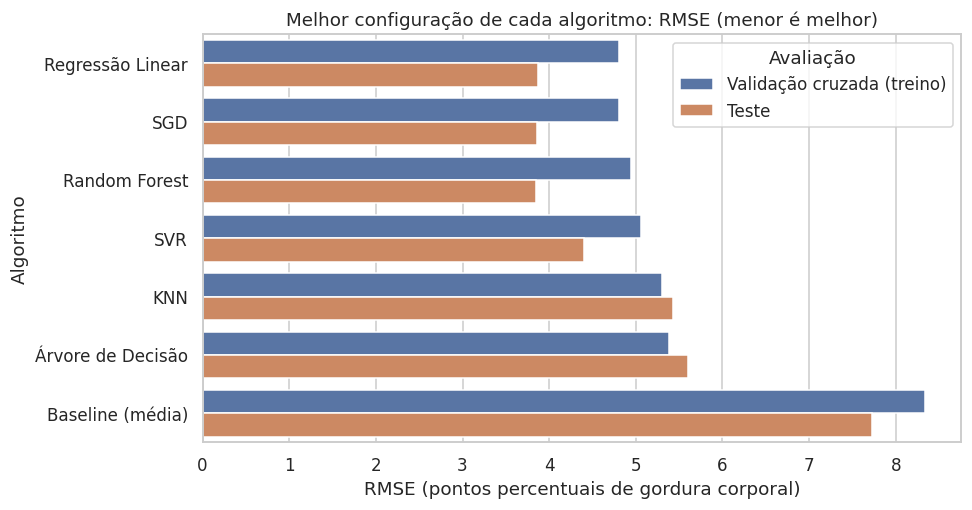

In [ ]:
df_res = pd.DataFrame(resultados)
tabela_final = df_res.sort_values("cv_rmse").reset_index(drop=True)
display(tabela_final.round(3))

# Melhor configuração por família: validação cruzada x teste
melhores = df_res.loc[df_res.groupby("familia")["cv_rmse"].idxmin()].copy()
grafico = melhores.melt(id_vars="familia", value_vars=["cv_rmse", "rmse_teste"],
                        var_name="Avaliação", value_name="RMSE")
grafico["Avaliação"] = grafico["Avaliação"].map(
    {"cv_rmse": "Validação cruzada (treino)", "rmse_teste": "Teste"})

plt.figure(figsize=(9, 4.8))
sns.barplot(data=grafico, y="familia", x="RMSE", hue="Avaliação",
            order=melhores.sort_values("cv_rmse")["familia"])
plt.title("Melhor configuração de cada algoritmo: RMSE (menor é melhor)")
plt.xlabel("RMSE (pontos percentuais de gordura corporal)")
plt.ylabel("Algoritmo")
plt.tight_layout()
plt.show()

In [ ]:
# Escolha do melhor modelo: menor RMSE na VALIDAÇÃO CRUZADA (sem olhar o teste)
candidatos = df_res[df_res["familia"] != "Baseline (média)"]
melhor = df_res.loc[candidatos["cv_rmse"].idxmin()]
base = df_res[df_res["familia"] == "Baseline (média)"].iloc[0]
modelo_final, prev_final = modelos[(melhor["familia"], melhor["hiperparametros"])]
ganho = (1 - melhor["rmse_teste"] / base["rmse_teste"]) * 100

display(Markdown(f"""
### Modelo escolhido: **{melhor['familia']}** com `{melhor['hiperparametros']}`

| | CV RMSE (treino) | RMSE (teste) | MAE (teste) | R² (teste) |
|---|---|---|---|---|
| **{melhor['familia']}** | {melhor['cv_rmse']:.2f} ± {melhor['cv_desvio']:.2f} | {melhor['rmse_teste']:.2f} | {melhor['mae_teste']:.2f} | {melhor['r2_teste']:.3f} |
| Baseline (prever a média) | {base['cv_rmse']:.2f} ± {base['cv_desvio']:.2f} | {base['rmse_teste']:.2f} | {base['mae_teste']:.2f} | {base['r2_teste']:.3f} |

O modelo **reduz o erro (RMSE) em {ganho:.0f}%** em relação ao baseline.
"""))


### Modelo escolhido: **Regressão Linear** com `fit_intercept=True (com escala)`

| | CV RMSE (treino) | RMSE (teste) | MAE (teste) | R² (teste) |
|---|---|---|---|---|
| **Regressão Linear** | 4.81 ± 0.28 | 3.87 | 3.13 | 0.749 |
| Baseline (prever a média) | 8.34 ± 0.79 | 7.72 | 6.39 | -0.000 |

O modelo **reduz o erro (RMSE) em 50%** em relação ao baseline.


### Por que esse modelo? (justificativa)

1. Foi o de **menor RMSE na validação cruzada**, escolha feita **sem usar o teste**.
2. O resultado no teste, comparado com a validação, indica se o modelo **generaliza**: números próximos sugerem que não houve superajuste.
3. O ganho sobre o baseline mostra que as medidas corporais **realmente carregam informação** sobre a gordura.
4. Quando dois modelos têm desempenho muito próximo (diferença menor que o desvio da validação cruzada), prefira o **mais simples e explicável**.

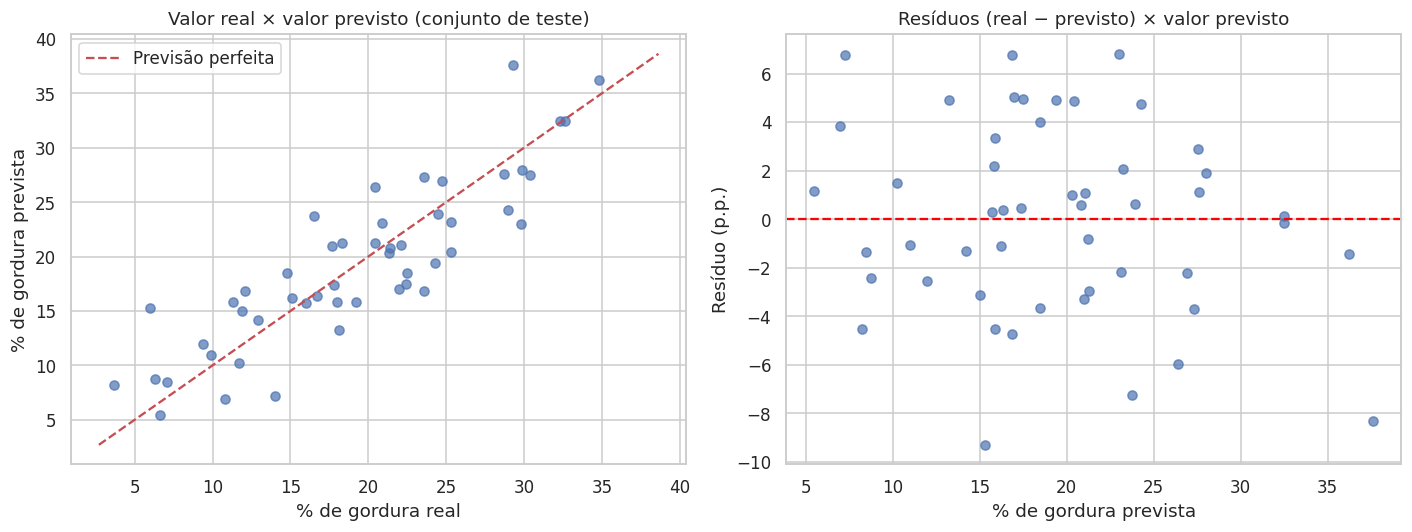

Erro médio absoluto: 3.13 p.p.
Previsões com erro de até 3 p.p.: 54% | até 5 p.p.: 84%


In [ ]:
# Análise do melhor modelo: previsto x real, resíduos e importância das variáveis
residuos = y_teste - prev_final
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

lim = [min(y_teste.min(), prev_final.min()) - 1, max(y_teste.max(), prev_final.max()) + 1]
axes[0].scatter(y_teste, prev_final, alpha=0.7)
axes[0].plot(lim, lim, "r--", label="Previsão perfeita")
axes[0].set(title="Valor real × valor previsto (conjunto de teste)",
            xlabel="% de gordura real", ylabel="% de gordura prevista")
axes[0].legend()

axes[1].scatter(prev_final, residuos, alpha=0.7)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(title="Resíduos (real − previsto) × valor previsto",
            xlabel="% de gordura prevista", ylabel="Resíduo (p.p.)")
plt.tight_layout()
plt.show()

dentro3 = (residuos.abs() <= 3).mean() * 100
dentro5 = (residuos.abs() <= 5).mean() * 100
print(f"Erro médio absoluto: {residuos.abs().mean():.2f} p.p.")
print(f"Previsões com erro de até 3 p.p.: {dentro3:.0f}% | até 5 p.p.: {dentro5:.0f}%")

**Como ler.** No gráfico da esquerda, quanto mais perto da linha tracejada, melhor a previsão. No da direita, queremos resíduos **espalhados aleatoriamente em torno de zero**; padrões (curvas, funil) indicam que o modelo erra de forma sistemática ou que o erro cresce em certas faixas.

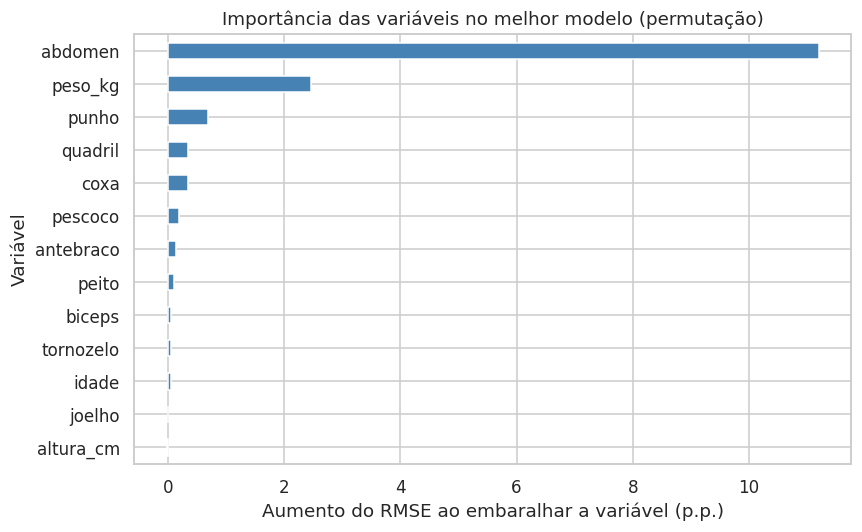

Variáveis mais importantes: abdomen, peso_kg, punho


In [ ]:
# Importância por permutação: quanto o erro piora ao embaralhar cada variável (conjunto de teste)
pi = permutation_importance(modelo_final, X_teste, y_teste, n_repeats=30, random_state=42,
                            scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=X_teste.columns).sort_values()

plt.figure(figsize=(8, 5))
imp.plot.barh(color="steelblue")
plt.title("Importância das variáveis no melhor modelo (permutação)")
plt.xlabel("Aumento do RMSE ao embaralhar a variável (p.p.)")
plt.ylabel("Variável")
plt.tight_layout()
plt.show()

print("Variáveis mais importantes:", ", ".join(imp.sort_values(ascending=False).index[:3]))

**Interpretação.** Variáveis com barras maiores são aquelas das quais o modelo **mais depende**: ao embaralhá-las, o erro aumenta bastante. Variáveis com barra próxima de zero praticamente **não contribuem** (muitas vezes porque a informação já está em outra feature correlacionada, o efeito da multicolinearidade visto na seção 6).

## 11) Conclusão final

In [ ]:
top_corr = corr_alvo.abs().sort_values(ascending=False).index[0]
top_imp = imp.sort_values(ascending=False).index[:3]
lista_imp = ", ".join(f"`{c}`" for c in top_imp)
melhor_knn = df_res[df_res["familia"] == "KNN"]["cv_rmse"].min()
melhor_arv = df_res[df_res["familia"] == "Árvore de Decisão"]["cv_rmse"].min()

display(Markdown(f"""
### Síntese dos resultados (gerada a partir desta execução)

- **Dados:** {len(df_bruto)} homens originais; após a limpeza ficaram **{len(X)}** (X: {X.shape[1]} features).
- **Variável mais correlacionada com o target:** `{top_corr}` (r = {corr_alvo[top_corr]:.2f}).
- **Modelo escolhido:** {melhor['familia']} — `{melhor['hiperparametros']}`.
- **Desempenho no teste:** MAE = {melhor['mae_teste']:.2f} p.p., RMSE = {melhor['rmse_teste']:.2f} p.p., R² = {melhor['r2_teste']:.3f}.
- **Baseline (prever a média):** RMSE = {base['rmse_teste']:.2f} p.p. → redução de erro de **{ganho:.0f}%**.
- **Variáveis mais importantes (permutação):** {lista_imp}.
- **Melhor CV RMSE por algoritmo:** KNN = {melhor_knn:.2f} | Árvore = {melhor_arv:.2f} | Escolhido = {melhor['cv_rmse']:.2f}.
"""))


### Síntese dos resultados (gerada a partir desta execução)

- **Dados:** 252 homens originais; após a limpeza ficaram **249** (X: 13 features).
- **Variável mais correlacionada com o target:** `abdomen` (r = 0.81).
- **Modelo escolhido:** Regressão Linear — `fit_intercept=True (com escala)`.
- **Desempenho no teste:** MAE = 3.13 p.p., RMSE = 3.87 p.p., R² = 0.749.
- **Baseline (prever a média):** RMSE = 7.72 p.p. → redução de erro de **50%**.
- **Variáveis mais importantes (permutação):** `abdomen`, `peso_kg`, `punho`.
- **Melhor CV RMSE por algoritmo:** KNN = 5.30 | Árvore = 5.39 | Escolhido = 4.81.


### O que foi aprendido

**Sobre o dataset.** As medidas de circunferência do tronco (principalmente o abdômen) concentram a maior parte do sinal sobre o % de gordura, enquanto a altura contribui pouco. Muitas features são redundantes entre si (multicolinearidade).

**Problemas de qualidade e decisões de pré-processamento.**
- Removi do `X` as colunas que **continham o target** (densidade, Brozek, massa magra) para evitar *target leakage*.
- Corrigi uma **altura impossível** (erro de digitação documentado) e removi poucas linhas com **target não confiável** (gordura truncada em zero e incoerência entre as duas fórmulas).
- Converti unidades por regra fixa (sem leakage) e **não removi outliers reais**.
- A padronização ficou **dentro de Pipeline**, ajustada só no treino (e por fold na validação cruzada).

**Gráficos que mais ajudaram.** O mapa de correlação (mostrou o que explica o target e a redundância entre features) e os scatterplots com reta (mostraram relação aproximadamente linear).

**Modelos e hiperparâmetros.** Testei Regressão Linear, Árvore, KNN, Random Forest, SGD e SVR, comparados a um baseline. Nas árvores, `max_depth`/`min_samples_leaf` controlam o equilíbrio entre subajuste e superajuste; no KNN, `n_neighbors` e a padronização foram decisivos; na Random Forest, o número de árvores estabiliza o resultado; no SGD, a taxa de aprendizagem (`eta0`) e o número de iterações decidem se o treino converge; no SVR, `C` e o kernel (linear × rbf) controlam a flexibilidade. A escolha foi feita por **validação cruzada** (RMSE), e o teste só reportou o desempenho final.

**Normalização.** Importante para o **KNN**; irrelevante para árvores, Random Forest e (nas previsões) para a Regressão Linear, como demonstrado na seção 9.

**Métricas que sustentam a escolha.** RMSE (principal, penaliza erros grandes e está em p.p.), apoiado por MAE (erro típico) e R² (ganho sobre prever a média).

### Limitações e próximos passos
- **Amostra pequena** (~250 homens) e **apenas homens**: o modelo não deve ser aplicado a mulheres ou outras populações.
- A medida de referência (pesagem subaquática) também tem erro, e a base contém pontos com erros de digitação (tratados aqui, mas indicam cautela).
- Com poucas linhas, o resultado no teste varia conforme a divisão: o ideal seria repetir a validação cruzada para o conjunto todo.
- Próximos passos: busca sistemática de hiperparâmetros (`GridSearchCV`), regularização (Ridge/Lasso) para lidar com a multicolinearidade, *gradient boosting* e coleta de dados mais diversos.
- **Uso exclusivamente educacional**, sem finalidade de diagnóstico.

### Referências
- Johnson, R. W. (1996). *Fitting Percentage of Body Fat to Simple Body Measurements*. Journal of Statistics Education, 4(1). Dados: https://jse.amstat.org/datasets/fat.txt
- Penrose, K., Nelson, A., Fisher, A. (1985). *Generalized Body Composition Prediction Equation for Men Using Simple Measurement Techniques*. Medicine and Science in Sports and Exercise, 17(2), 189.
- Documentação do scikit-learn: https://scikit-learn.org/stable/

### Checklist da Questão 1

| Item | Status |
|---|---|
| Dataset real e público, com link da fonte | ✅ |
| Dataset não utilizado em aula | ☐ confirmar com o material da disciplina |
| Problema e target explicados | ✅ |
| Dados em DataFrame, X e y separados | ✅ |
| Amostras, features, tipos, estatísticas, ausentes e duplicidades verificados | ✅ |
| Pré-processamento justificado | ✅ |
| Data leakage evitado (colunas derivadas do target removidas; scaler dentro do Pipeline) | ✅ |
| Pelo menos 2 gráficos interpretados | ✅ (4 gráficos) |
| Divisão treino/teste com `random_state=42` | ✅ |
| Pelo menos 2 algoritmos e 3 configurações de hiperparâmetros | ✅ (6 algoritmos, várias configurações) |
| Necessidade de normalização explicada e testada | ✅ |
| Métricas adequadas comparadas (MAE, RMSE, R²) | ✅ |
| Melhor modelo justificado | ✅ |
| Conclusão final | ✅ |
| Notebook executa do início ao fim sem erros | ☐ rodar *Ambiente de execução → Reiniciar e executar tudo* |